# K Means implementation

Esta implementacion esta hecha con mucha fe y pocas optimizaciones

In [125]:
# Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [126]:
class Point:
    def __init__(self, values, i):
        self.values = np.array(values)
        self.i = i

    def distance(self, other):
        return np.linalg.norm(self.values - other.values)

In [127]:
class Cluster:
    def __init__(self, centroid, i):
        self.centroid = Point(centroid, i)
        self.category = None
        self.points = []

    def update_centroid(self):
        if len(self.points) == 0:
            return
        new_centroid_values = np.mean([p.values for p in self.points], axis=0)
        self.centroid = Point(new_centroid_values, self.centroid.i)

In [128]:
def WCSS(clusters):
    # I searches for a way to calculate the variance of the clusters
    # https://math.stackexchange.com/questions/1009297/variances-for-k-means-clustering
    return sum(sum(p.distance(c.centroid) ** 2 for p in c.points) for c in clusters)

In [129]:
def step_kmeans(data, k, epochs=100):
    # Select k random points as centroids
    nums = np.random.choice(data.shape[0], k, replace=False)
    clusters = [Cluster(data.iloc[i].values, i) for i in nums]
    past_var = np.inf
    for _ in range(epochs):

        # Clear points in each cluster
        for cluster in clusters:
            cluster.points = []

        # Assign points to the nearest cluster
        for i, (_, row) in enumerate(data.iterrows()):
            point = Point(row.values, i)
            closest_cluster = min(clusters, key=lambda c: point.distance(c.centroid))
            closest_cluster.points.append(point)
        # Update centroids
        for cluster in clusters:
                cluster.update_centroid()
        # Get the variance of the clusters
        var = WCSS(clusters)
        # If the variance change is not significant, we can stop
        # Is like the variace has converged
        if abs(past_var - var) < 1e-4:
            break
        past_var = var
    return clusters

In [130]:
def cluster_categories(clusters, X, y):
    # Assign categories to clusters based on the majority class of the points in each cluster
    for cluster in clusters:
        if len(cluster.points) == 0:
            continue
        point_indices = [p.i for p in cluster.points]
        point_labels = y.iloc[point_indices]
        majority_category = point_labels.mode()[0]
        cluster.category = majority_category

In [131]:
def kmeans(X, y, k, max_iters=100):
    kmeans_results = []
    for _ in range(max_iters):
        clusters = step_kmeans(X, k)
        kmeans_results.append(clusters)
    # We select the best result based on the variance of the clusters
    best_clusters = min(kmeans_results, key=WCSS)
    cluster_categories(best_clusters, X, y)
    return best_clusters

In [132]:
def classify_point(point, clusters):
    closest_cluster = min(clusters, key=lambda c: point.distance(c.centroid))
    return closest_cluster.category

# Train KMeans

In [133]:
data = pd.read_csv('datasets_clasificacion/completo_30_train.csv')
data.head(1)

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,0.982686,-0.52764,0.173598,-1.087543,-0.727661,0.491455,0.79146,-0.596717,0.354587,0.255419,0.857462,0.437825,1.86318,0


In [134]:
y_train = data['target']
X_train = data.drop(columns=['target'])

In [135]:
X_train.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,0.982686,-0.527640,0.173598,-1.087543,-0.727661,0.491455,0.791460,-0.596717,0.354587,0.255419,0.857462,0.437825,1.863180
1,0.957937,-0.745511,1.255504,0.839386,0.063252,1.131923,1.306553,-0.596717,1.343233,0.297587,1.032095,0.159563,1.749108
2,0.401078,-0.612894,1.777803,-1.235769,0.656436,0.491455,0.707363,-0.170491,-0.425924,-0.166255,0.595512,0.262081,0.429136
3,0.772317,-0.593949,-0.012937,-0.168547,0.392799,0.907759,1.243480,-1.193434,0.597412,0.803596,0.595512,0.408534,2.498722
4,-1.863482,0.107025,0.210905,0.098259,-0.266295,0.971806,0.822996,-0.340981,0.389276,-0.735516,-0.670576,1.155447,-0.401958


In [136]:
history = []
for k in range(1, 15):
    clusters = kmeans(X_train, y_train, k)
    print(f'K={k}, WCSS={WCSS(clusters)}')
    history.append(WCSS(clusters))

K=1, WCSS=1611.9999999999995
K=2, WCSS=1161.8906566908336
K=3, WCSS=884.8234437567276
K=4, WCSS=806.3360075527526
K=5, WCSS=745.481563870122
K=6, WCSS=706.6698903364048
K=7, WCSS=660.1856683203205
K=8, WCSS=619.6245421833501
K=9, WCSS=586.7906574505871
K=10, WCSS=573.8125931818386
K=11, WCSS=548.5860062496783
K=12, WCSS=515.2780245533911
K=13, WCSS=501.20822297086573
K=14, WCSS=474.92286031782237


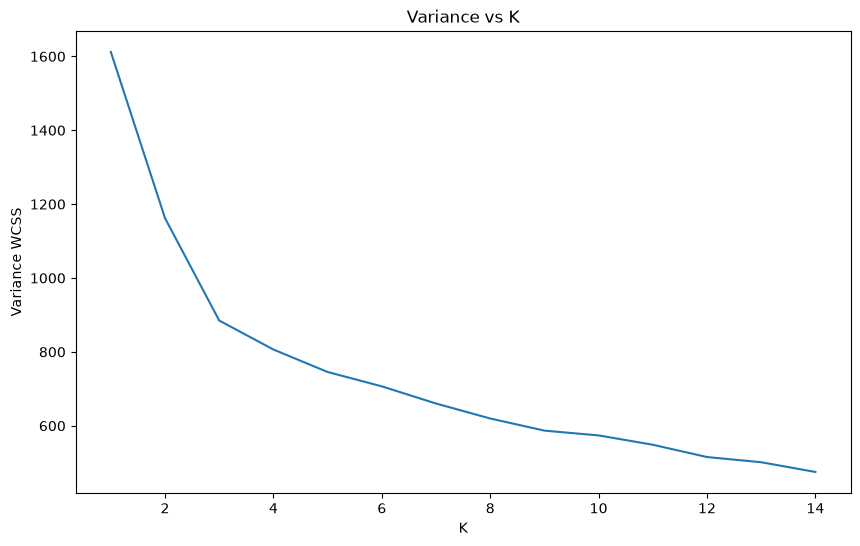

In [137]:
plt.figure(figsize=(10, 6))
plt.title('Variance vs K')
plt.xlabel('K')
plt.ylabel('Variance WCSS')
plt.plot(range(1, 15), history)

Esto lo hago en español para la documentacion.

Podemos apreciar que la varianza obviamente disminuye a medida que aumentamos el k, podriamos alcanzar una varianza 0 eligiendo k = n, pero esto viola todo el principio de generalizar por clusters, ademas podemos apreciar que a partir de k=3 los cambios en la varianza son marginalmente menores a los primeros saltos, ademas dado que nuestor objetivo es clasificar en 3 subgrupos nuestro caso ideal aspiraria a que el k-means encontrara justamente esos 3 clusters, asi que dado el contexto de nuestro problema y el analisis de la varianza elegimos un k=3.

In [138]:
clusters = kmeans(data.iloc[:, :-1], data.iloc[:, -1], 3, max_iters=100)

# Testing

In [139]:
X_test = pd.read_csv('datasets_clasificacion/completo_30_test.csv')
y_test = X_test['target']
X_test = X_test.drop(columns=['target'])

In [140]:
X_test.head(1)

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,0.252582,0.069135,1.143582,-0.316772,0.063252,0.811689,1.296041,-0.511472,2.089053,0.289153,0.333563,0.833249,1.423189


In [141]:
y_test.head(1)

0    0
Name: target, dtype: int64

In [142]:
error_count = 0
for i in range(len(X_test)):
    point = Point(X_test.iloc[i].values, i)
    predicted_category = classify_point(point, clusters)
    print(f'Predicted: {predicted_category}, Actual: {y_test.iloc[i]}')
    if predicted_category != y_test.iloc[i]:
        error_count += 1

Predicted: 0, Actual: 0
Predicted: 1, Actual: 1
Predicted: 0, Actual: 0
Predicted: 0, Actual: 0
Predicted: 0, Actual: 0
Predicted: 0, Actual: 0
Predicted: 2, Actual: 2
Predicted: 1, Actual: 1
Predicted: 0, Actual: 1
Predicted: 2, Actual: 2
Predicted: 2, Actual: 1
Predicted: 1, Actual: 1
Predicted: 2, Actual: 2
Predicted: 1, Actual: 1
Predicted: 0, Actual: 0
Predicted: 2, Actual: 2
Predicted: 1, Actual: 1
Predicted: 0, Actual: 0
Predicted: 2, Actual: 2
Predicted: 2, Actual: 2
Predicted: 1, Actual: 1
Predicted: 2, Actual: 2
Predicted: 2, Actual: 2
Predicted: 2, Actual: 2
Predicted: 2, Actual: 1
Predicted: 2, Actual: 2
Predicted: 0, Actual: 0
Predicted: 1, Actual: 1
Predicted: 0, Actual: 0
Predicted: 1, Actual: 1
Predicted: 0, Actual: 0
Predicted: 1, Actual: 1
Predicted: 2, Actual: 2
Predicted: 1, Actual: 1
Predicted: 1, Actual: 1
Predicted: 2, Actual: 2
Predicted: 1, Actual: 1
Predicted: 1, Actual: 1
Predicted: 1, Actual: 1
Predicted: 0, Actual: 0
Predicted: 2, Actual: 2
Predicted: 0, Ac

In [143]:
print(f'Total errors: {error_count} out of {len(X_test)}')
print(f'Accuracy: {(len(X_test) - error_count) / len(X_test) * 100:.2f}%')

Total errors: 3 out of 54
Accuracy: 94.44%


Podemos apreciar que el accuracy es del 94% por lo tanto el kmeans es efectivo en clasificar la gran mayoria de los puntos, comentiendo unos ligeros errores, pero en general es un clasificador efectivo.